# Diabetes Prediction Using Machine Learning

## Baseline Model Development




## 1. Import Required Libraries


In [1]:
from pathlib import Path
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

## 2. Define Project Paths


In [3]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_RELATIVE_PATH = Path("data") / "processed" / "diabetes_cleaned.csv"
TABLES_RELATIVE_DIR = Path("outputs") / "tables" 
FIGURES_RELATIVE_DIR = Path("outputs") / "figures" 
REPORTS_RELATIVE_DIR = Path("reports") 
MODELS_RELATIVE_DIR = Path("models")

DATASET_PATH = PROJECT_ROOT / DATASET_RELATIVE_PATH
TABLES_DIR = PROJECT_ROOT / TABLES_RELATIVE_DIR
FIGURES_DIR = PROJECT_ROOT / FIGURES_RELATIVE_DIR
REPORTS_DIR = PROJECT_ROOT / REPORTS_RELATIVE_DIR
MODELS_DIR = PROJECT_ROOT / MODELS_RELATIVE_DIR

for directory in [TABLES_DIR, FIGURES_DIR, REPORTS_DIR, MODELS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print(f"Dataset path: {DATASET_RELATIVE_PATH}")
print(f"Tables directory: {TABLES_RELATIVE_DIR}")
print(f"Figures directory: {FIGURES_RELATIVE_DIR}")
print(f"Reports directory: {REPORTS_RELATIVE_DIR}")

Dataset path: data\processed\diabetes_cleaned.csv
Tables directory: outputs\tables
Figures directory: outputs\figures
Reports directory: reports


## 3. Load and Validate Dataset


In [4]:
EXPECTED_COLUMNS = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Required dataset was not found: {DATASET_RELATIVE_PATH}")

df = pd.read_csv(DATASET_PATH)
missing_columns = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
extra_columns = sorted(set(df.columns) - set(EXPECTED_COLUMNS))

if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

if extra_columns:
    raise ValueError(f"Unexpected columns found: {extra_columns}")

if df.isna().sum().sum() != 0:
    raise ValueError("The cleaned dataset contains missing values. Week 9 requires a fully cleaned dataset.")

print("Cleaned dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Cleaned dataset loaded successfully.
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 4. Define selected features and target




In [14]:
SELECTED_FEATURES = [
    "Glucose",
    "BMI",
    "Age",
    "Pregnancies",
    "DiabetesPedigreeFunction"
]

TARGET = "Outcome"

X = df[SELECTED_FEATURES].copy()
y = df[TARGET].copy()

print("Selected features:")
print(SELECTED_FEATURES)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget distribution (%):")
print(y.value_counts(normalize=True).mul(100).round(2))

Selected features:
['Glucose', 'BMI', 'Age', 'Pregnancies', 'DiabetesPedigreeFunction']

Feature shape: (768, 5)
Target shape: (768,)

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Target distribution (%):
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


## 5. Create Identical Train/Test Split

A single stratified 80/20 split is created using the row index and target variable. The same train and test indices are reused for both experiments to make the comparison fair.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 614
Testing samples : 154

Training target distribution:
Outcome
0    400
1    214
Name: count, dtype: int64

Testing target distribution:
Outcome
0    100
1     54
Name: count, dtype: int64


## Check Class Imbalance

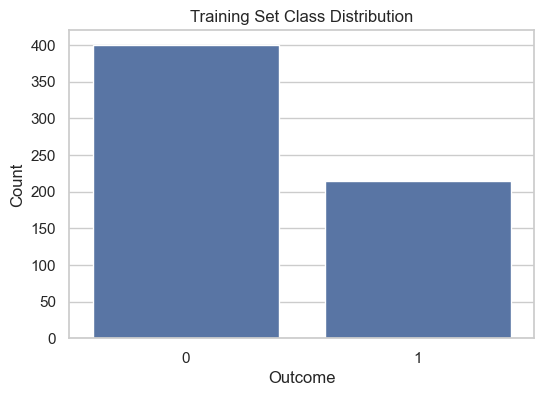

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(x=y_train)

plt.title("Training Set Class Distribution")
plt.xlabel("Outcome")
plt.ylabel("Count")

plt.show()

##  Create the Two Models

Model 1 — Logistic Regression
Good baseline and easy to interpret.
Model 2 — Random Forest
Can capture non-linear relationships between the clinical variables.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight=None
)

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

## Install and import SMOTE for class balancing


In [17]:
!pip install imbalanced-learn
from imblearn.over_sampling import SMOTE


   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Create Pipelines with Scaling + SMOTE
This is an important improvement over simply doing SMOTE before splitting.

In [19]:
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipelines = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(
            random_state=RANDOM_STATE
        )),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(
            random_state=RANDOM_STATE
        )),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE
        ))
    ])
}

## Train both models


In [20]:
trained_models = {}

for name, pipeline in pipelines.items():

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Random Forest trained successfully.


## Generate Predictions


In [21]:
predictions = {}
probabilities = {}

for name, model in trained_models.items():

    predictions[name] = model.predict(X_test)

    probabilities[name] = model.predict_proba(X_test)[:, 1]

    print(f"{name} predictions generated.")

Logistic Regression predictions generated.
Random Forest predictions generated.


## Model Comparison tables



In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

for name in trained_models.keys():

    y_pred = predictions[name]
    y_prob = probabilities[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest,0.7208,0.5902,0.6667,0.6261,0.8223,0.6992
1,Logistic Regression,0.7208,0.5846,0.7037,0.6387,0.8059,0.6549


## Classification report



In [24]:
from sklearn.metrics import classification_report

for name in trained_models.keys():

    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=["Non-Diabetic", "Diabetic"],
            zero_division=0
        )
    )

Logistic Regression
              precision    recall  f1-score   support

Non-Diabetic       0.82      0.73      0.77       100
    Diabetic       0.58      0.70      0.64        54

    accuracy                           0.72       154
   macro avg       0.70      0.72      0.71       154
weighted avg       0.74      0.72      0.73       154

Random Forest
              precision    recall  f1-score   support

Non-Diabetic       0.81      0.75      0.78       100
    Diabetic       0.59      0.67      0.63        54

    accuracy                           0.72       154
   macro avg       0.70      0.71      0.70       154
weighted avg       0.73      0.72      0.72       154



## Confusion matrix



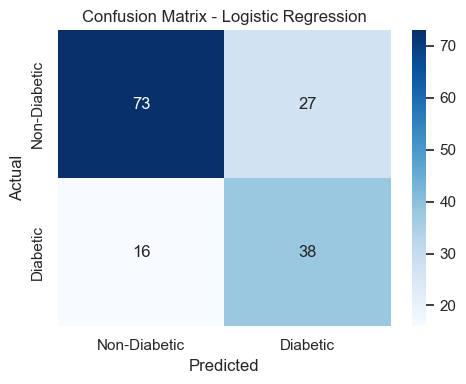

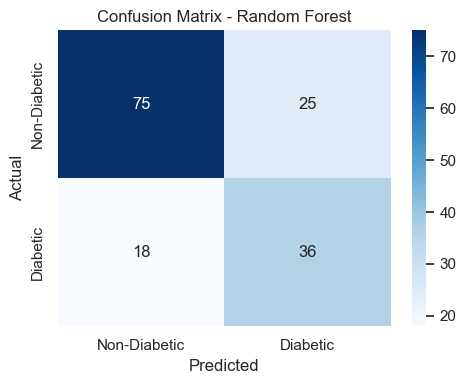

In [26]:
from sklearn.metrics import confusion_matrix

for name in trained_models.keys():

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-Diabetic", "Diabetic"],
        yticklabels=["Non-Diabetic", "Diabetic"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()

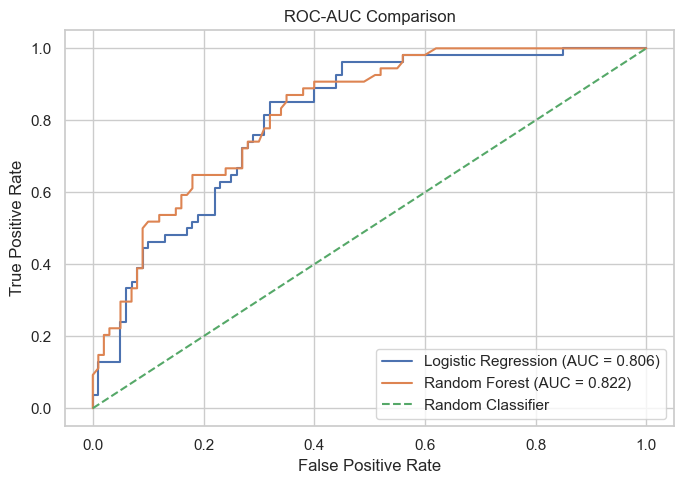

In [27]:
# ============================================================
# 11. ROC-AUC CURVE
# ============================================================

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(7, 5))

for name in trained_models.keys():

    y_prob = probabilities[name]

    fpr, tpr, _ = roc_curve(y_test, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC-AUC Comparison")

plt.legend()

plt.tight_layout()

plt.show()

## cross validation



In [29]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

for name, model in pipelines.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_comparison = pd.DataFrame(cv_results)

cv_comparison.round(4)

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
0,Logistic Regression,0.7752,0.6663,0.7245,0.6915,0.8475
1,Random Forest,0.7557,0.6393,0.6962,0.6655,0.8203


## Best Model



In [30]:
# ============================================================
# 14. BEST MODEL
# ============================================================

comparison_df = comparison_df.sort_values(
    by=["ROC-AUC", "F1-Score", "Recall"],
    ascending=False
).reset_index(drop=True)

best_model_name = comparison_df.loc[0, "Model"]

print("Best Model:", best_model_name)

print("\nFinal Test-Set Performance:")
print(comparison_df.iloc[0])

Best Model: Random Forest

Final Test-Set Performance:
Model        Random Forest
Accuracy          0.720779
Precision         0.590164
Recall            0.666667
F1-Score          0.626087
ROC-AUC           0.822315
PR-AUC            0.699208
Name: 0, dtype: object


## Final Model



In [33]:
final_model = trained_models[best_model_name]

print("Final model selected:", best_model_name)

Final model selected: Random Forest


## Save Final Selected Model



In [35]:
import joblib
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "diabetes_selected_features_final_model.joblib"

joblib.dump(
    final_model,
    model_path
)

print("Final model saved successfully!")
print("Location:", model_path)

Final model saved successfully!
Location: models\diabetes_selected_features_final_model.joblib
